In [2]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

print("Libraries imported successfully")

Libraries imported successfully


In [3]:
np.random.seed(42)

df = pd.DataFrame({
    "Region": np.random.choice(["North", "South"], 100),
    "Daily_Sales": np.random.normal(5200, 800, 100),
    "Marketing": np.random.choice(["Campaign", "No_Campaign"], 100),
    "Customer_Spending": np.random.normal(1200, 250, 100)
})

# Add a campaign spending effect for demonstration
df.loc[df["Marketing"] == "Campaign", "Customer_Spending"] += 150

df.head()

,Region,Daily_Sales,Marketing,Customer_Spending
0,North,5790.773264,No_Campaign,932.276875
1,South,5337.094625,No_Campaign,1320.618104
2,North,5107.481374,Campaign,1294.134304
3,North,4959.117044,No_Campaign,1378.500124
4,North,4017.182408,No_Campaign,1318.309406


In [4]:
sales = df["Daily_Sales"]

# Hypotheses
# H0: Mean sales = 5000
# H1: Mean sales != 5000

t_stat, p_value = stats.ttest_1samp(sales, popmean=5000)

# 95% Confidence Interval
mean_sales = sales.mean()
std_error = stats.sem(sales)

ci = stats.t.interval(
    confidence=0.95,
    df=len(sales) - 1,
    loc=mean_sales,
    scale=std_error
)

print("Sample Mean:", round(mean_sales, 2))
print("T-statistic:", round(t_stat, 4))
print("P-value:", round(p_value, 4))
print("95% Confidence Interval:", ci)

if p_value < 0.05:
    print("Reject H0: Average sales are significantly different from ₹5,000.")
else:
    print("Fail to reject H0: Insufficient evidence that average sales differ from ₹5,000.")

Sample Mean: 5175.85
T-statistic: 2.3418
P-value: 0.0212
95% Confidence Interval: (np.float64(5026.849493921654), np.float64(5324.853955199402))
Reject H0: Average sales are significantly different from ₹5,000.


In [5]:
north_sales = df.loc[df["Region"] == "North", "Daily_Sales"]
south_sales = df.loc[df["Region"] == "South", "Daily_Sales"]

# H0: North mean = South mean
# H1: North mean != South mean

t_stat, p_value = stats.ttest_ind(
    north_sales,
    south_sales,
    equal_var=False  # Welch's t-test
)

print("North Mean Sales:", round(north_sales.mean(), 2))
print("South Mean Sales:", round(south_sales.mean(), 2))
print("Difference:", round(north_sales.mean() - south_sales.mean(), 2))
print("T-statistic:", round(t_stat, 4))
print("P-value:", round(p_value, 4))

if p_value < 0.05:
    print("Reject H0: Significant difference in regional average sales.")
else:
    print("Fail to reject H0: No sufficient evidence of a regional sales difference.")

North Mean Sales: 5247.68
South Mean Sales: 5119.42
Difference: 128.26
T-statistic: 0.8685
P-value: 0.3873
Fail to reject H0: No sufficient evidence of a regional sales difference.


In [6]:
difference = north_sales.mean() - south_sales.mean()

se_diff = np.sqrt(
    north_sales.var(ddof=1) / len(north_sales)
    + south_sales.var(ddof=1) / len(south_sales)
)

df_welch = (
    (north_sales.var(ddof=1) / len(north_sales)
     + south_sales.var(ddof=1) / len(south_sales)) ** 2
    /
    (
        (north_sales.var(ddof=1) / len(north_sales)) ** 2
        / (len(north_sales) - 1)
        +
        (south_sales.var(ddof=1) / len(south_sales)) ** 2
        / (len(south_sales) - 1)
    )
)

critical_value = stats.t.ppf(0.975, df_welch)

ci_lower = difference - critical_value * se_diff
ci_upper = difference + critical_value * se_diff

print("95% CI for North-South difference:", (ci_lower, ci_upper))

95% CI for North-South difference: (np.float64(-164.825238146318), np.float64(421.3534117505014))


In [7]:
campaign = df.loc[
    df["Marketing"] == "Campaign", "Customer_Spending"
]

no_campaign = df.loc[
    df["Marketing"] == "No_Campaign", "Customer_Spending"
]

# H0: Campaign mean <= No campaign mean
# H1: Campaign mean > No campaign mean

t_stat, p_value = stats.ttest_ind(
    campaign,
    no_campaign,
    equal_var=False,
    alternative="greater"
)

print("Campaign Average Spending:", round(campaign.mean(), 2))
print("No Campaign Average Spending:", round(no_campaign.mean(), 2))
print("T-statistic:", round(t_stat, 4))
print("P-value:", round(p_value, 4))

if p_value < 0.05:
    print("Reject H0: Evidence suggests campaign customers spend more.")
else:
    print("Fail to reject H0: Insufficient evidence that campaign customers spend more.")

Campaign Average Spending: 1348.6
No Campaign Average Spending: 1201.3
T-statistic: 2.6941
P-value: 0.0043
Reject H0: Evidence suggests campaign customers spend more.


<Figure size 800x500 with 0 Axes>

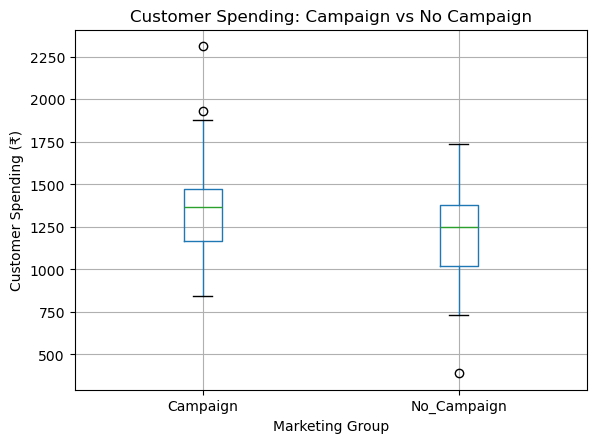

In [8]:
plt.figure(figsize=(8, 5))

df.boxplot(
    column="Customer_Spending",
    by="Marketing"
)

plt.title("Customer Spending: Campaign vs No Campaign")
plt.suptitle("")
plt.xlabel("Marketing Group")
plt.ylabel("Customer Spending (₹)")
plt.show()